# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Бойко Роман'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-32'      # напр. 'КН-31'
ВАРІАНТ = 4     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 4 · Бойко Роман, ШІ-32, «Друк-Сервіс»
Підприємство «Друк-Сервіс» виготовляє поліграфію. Одиниця виміру плану: тис. прим./тиждень.

                          Буклет  Каталог  Календар  Плакат  ЗАПАС
Крейдований папір, кг          5        0         0       0    815
Офсетний папір, кг             1        0         5       2    344
Фарба, кг                      2        4         6       5    840
Друкарська машина, год         3        0         5       3    840
Різка й фальцювання, год       2        1         2       5    382

                    Буклет  Каталог  Календар  Плакат
Прибуток з одиниці      41       50        54      26

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Різка й фальцювання, год
  ціна:   8.3 за одиницю
  обсяг:  до 144 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

pulp не встановлено — скористайтеся scipy.optimize.linprog


---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

**Змінні рішення:**
x1 - обсяг випуску буклетів (тис. прим./тиждень)
x2 - обсяг випуску каталогів (тис. прим./тиждень)
x3 - обсяг випуску календарів (тис. прим./тиждень)
x4 - обсяг випуску плакатів (тис. прим./тиждень)

**Цільова функція:**
41x1 + 50x2 + 54x3 +26x4 -> max

**Обмеження:**
5x1 <= 815 (Крейдований папір, кг)
x1 + 5x3 + 2x4 <= 344 (Офсетний папір, кг)
2x_1 + 4x_2 + 6x_3 + 5x_4 <= 840 (Фарба, кг)
3x_1 + 5x_3 + 3x_4 <= 840 (Друкарська машина, год)
2x_1 + 1x_2 + 2x_3 + 5x_4 <= 382 (Різка й фальцювання, год)

**Невід'ємність:**
x1, x2, x3, x4 >= 0

### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**
Запас ресурсу є параметром, оскільки це фіксована величина на поточний період, яку ми не можемо змінювати, а змінні рішення — це ті величини, якими ми безпосередньо керуємо.

Якби підприємство могло докуповувати ресурс у будь-якій кількості, це обмеження перестало б бути жорстким. Він став би новою змінною рішення, а до цільової функції додалися б витрати на його придбання зі знаком мінус.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [114.6666667, 152.6666667, 0, 0]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 12334.66667             # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [114.6666667, 152.6666667, 0, 0] | прибуток 12334.66667


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# ВАШ КОД
from scipy.optimize import linprog


c = [-41, -50, -54, -26]

A = [
    [5, 0, 0, 0],
    [1, 0, 5, 2],
    [2, 4, 6, 5],
    [3, 0, 5, 3],
    [2, 1, 2, 5]
]


b = [815, 344, 840, 840, 382]

bounds = [(0, None), (0, None), (0, None), (0, None)]

res = linprog(c, A_ub=A, b_ub=b, bounds=bounds, method='highs')

план = res.x.tolist()
прибуток = -res.fun
print(план)
print(прибуток)


[114.66666666666667, 152.66666666666666, 0.0, 0.0]
12334.666666666668


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крейдований папір, кг | 573,3333333 | 0 | 815 | 1E+30 | 241,6666667 |
| Офсетний папір, кг | 114,6666667 | 0 | 344 | 1E+30 | 229,3333333 |
| Фарба, кг | 840 | 9,83333333 | 840 | 688 | 290 |
| Друкарська машина, год | 344 | 0 | 840 | 1E+30 | 496 |
| Різка й фальцювання, год | 382 | 10,66666667 | 382 | 72,5 | 172 |


**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

У дефіциті Фарба та Різка й фальцювання. Їхнє кінцеве значення дорівнює запасу, тобто ресурс витрачено повністю, і вони мають ненульову тіньову цін. Решта ресурсів — у надлишку, бо їхні кінцеві значення менші за запас, а тіньова ціна дорівнює нулю.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Буклет | 114,6666667 | 0 | 41 | 59 | 16 |
| Каталог | 152,6666667 | 0 | 50 | 32 | 19,75 |
| Календар | 0 | -26,33333333 | 54 | 26,33333333 | 1E+30 |
| Плакат | 0 | -76,5 | 26 | 76,5 | 1E+30 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Зовсім не виробляються Календар та Плакат. Щоб Календар увійшов у план, прибуток з його одиниці мусить зрости на 26,33. Для Плаката ця цифра становить 76,5.

---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# ВАШ КОД

b_new = b.copy()
b_new[4] += 1

res_new = linprog(c, A_ub=A, b_ub=b_new, bounds=bounds, method='highs')

new_план = res_new.x.tolist()
new_прибуток = -res_new.fun
diff = new_прибуток - прибуток

print(f"Базовий прибуток: {прибуток:.4f}")
print(f"Новий прибуток: {new_прибуток:.4f}")
print(f"Приріст прибутку (факт): {diff:.4f}")
print(f"Тіньова ціна (Excel): 10.6667")

Базовий прибуток: 12334.6667
Новий прибуток: 12345.3333
Приріст прибутку (факт): 10.6667
Тіньова ціна (Excel): 10.6667


**Відповідь 5.1:** *(приріст прибутку = ..., тіньова ціна зі звіту = ..., збігаються?)*

Приріст прибутку дорівнює 10.6667, тіньова ціна зі звіту також становить 10.6667.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

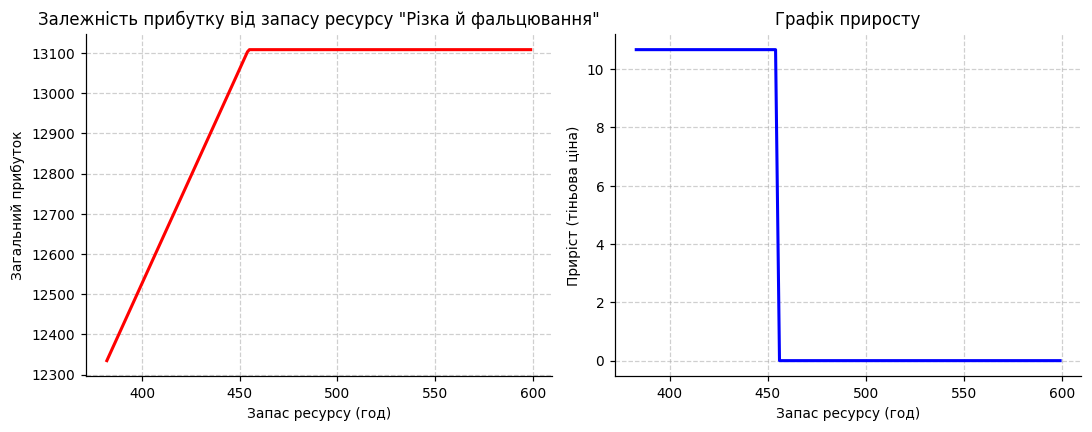

In [8]:
# ВАШ КОД
import numpy as np
profits = []
capacity = np.arange(382, 600)
for cap in capacity:
    b_test = b.copy()
    b_test[4] = cap
    res_test = linprog(c, A_ub=A, b_ub=b_test, method='highs')
    profits.append(-res_test.fun)
profits = np.array(profits)
diffs = np.diff(profits)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(capacity, profits, color="red", lw=2)
ax1.set_ylabel('Загальний прибуток')
ax1.set_xlabel('Запас ресурсу (год)')
ax1.set_title('Залежність прибутку від запасу ресурсу "Різка й фальцювання"')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(capacity[1:], diffs, color="blue", lw=2)
ax2.set_ylabel('Приріст (тіньова ціна)')
ax2.set_xlabel('Запас ресурсу (год)')
ax2.set_title('Графік приросту')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*

Запас ресурсу можна збільшувати на 72,5 одиниці, тобто до  382 + 72,5 = 454,5 год, доки тіньова ціна не зміниться. Знайдена межа точно збігається з показником «Припустиме збільшення» зі звіту Excel. На графіку праворуч це так само підтверджується: лінія тримається горизонтально на рівні ~10,67, а після позначки 454 відбувається різкий злам, оскільки вступає в дію інше обмеження.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
# ВАШ КОД
#ціна:   8.3 за одиницю
#обсяг:  до 144 одиниць
#Припустиме Збільшення = 72.5
new_pr = 8.3
new_cap = 144

shadow_price = 10.667
ass_increase = 72.5
av_diff = min(ass_increase, new_cap)
calculated_winning = av_diff * (shadow_price-new_pr)
b_new = b.copy()
b_new[4] += av_diff
res_new = linprog(c, A_ub=A, b_ub=b_new, bounds=bounds, method='highs')
new_profit = -res_new.fun
zakup = av_diff * new_pr
net_new_profit = new_profit - zakup

actual_winning = net_new_profit - прибуток
print(f"Обсяг закупівлі: {av_diff} год")
print(f"Очікуваний виграш: {calculated_winning:.2f}")
print(f"Фактичний виграш: {actual_winning:.2f}")

Обсяг закупівлі: 72.5 год
Очікуваний виграш: 171.61
Фактичний виграш: 171.58


**Відповідь 6.1:**

* Брати чи ні і чому:

Брати, оскільки тіньова ціна ресурсу вища за ціну постачальника. Кожна додаткова година принесе 10,67 - 8,3 = 2,37 одиниць чистого прибутку.

* Скільки одиниць має сенс купити і чому не більше:

Має сенс купити рівно 72,5 одиниць. Купувати запропоновані 144 одиниці не можна, оскільки після 72,5 додаткових годин ресурс перестане бути дефіцитним, його тіньова ціна впаде до нуля, і кожна наступна куплена година приноситиме лише збитки.

* Очікуваний виграш:

72,5 × (10,6667 - 8,3) = 171,58

* Перевірка прямим розв'язанням дала:
171,58

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
# ВАШ КОД
resourses_used = np.dot(A, план)
ненульових = sum(1 for p in план if p>1e-5)
звязних =  sum(1 for i in range(len(b)) if abs(resourses_used[i] - b[i]) < 1e-5)
print(f"Ненульових змінних: {ненульових}")
print(f"Зв'язних обмежень: {звязних}")



Ненульових змінних: 2
Зв'язних обмежень: 2


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** *(чи збіглися числа; що означала б розбіжність на практиці)*
Числа збіглися: маємо 2 ненульові змінні та 2 зв'язні обмеження.

Розбіжність на практиці свідчила б про помилку в розрахунках. Підприємство не може випускати більше видів рентабельної продукції, ніж має повністю вичерпаних дефіцитних ресурсів, які формують цей оптимальний план.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
# ВАШ КОД
# 1
print(f"Без умови цілочисельності: {план}, прибуток: {прибуток}")

# 2
new_plan_rounded = np.round(план)
res_used = np.dot(A, new_plan_rounded)
is_legal = np.all(res_used<=b)
profit_rounded = np.dot(c, new_plan_rounded)
print(f"Округлений план: {new_plan_rounded}, прибуток: {profit_rounded}, допустимий: {"Так" if is_legal else "Ні"}")

# 3

res_int = linprog(c, A_ub=A, b_ub=b, method='highs', integrality=1)
plan_int = np.round(res_int.x)
profit_int = -res_int.fun
print(f"цілочисельний оптимум: план: {plan_int}, прибуток: {profit_int}")

Без умови цілочисельності: [114.66666666666667, 152.66666666666666, 0.0, 0.0], прибуток: 12334.666666666668
Округлений план: [115. 153.   0.   0.], прибуток: -12365.0, допустимий: Ні
цілочисельний оптимум: план: [114. 153.   0.   0.], прибуток: 12324.0


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | [114.66666666666667, 152.66666666666666, 0.0, 0.0] | 12334.666666666668 | Так |
| округлений | [115. 153.   0.   0.]  | -12365.0 | Ні |
| цілочисельний оптимум | [114. 153.   0.   0.] | 12324.0 | Так |

**Висновок:** *(чи можна округлювати і чому)*

Округлювати план не можна, оскільки це призводить до порушення обмежень. У нашому випадку округлення вимагає виробити 115 буклетів та 153 каталоги, для чого потрібно 2*115 + 4*153 = 842 кг фарби. Але наш запас становить лише 840 кг, тому такий план фізично недійсний. Справжній цілочисельний оптимум дає трохи менший, але реальний прибуток, повністю вписуючись у ліміти ресурсів.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# ВАШ КОД — впишіть свої дані
постачальники = ['Брюгге','Осло','Йорк'] 
споживачі = ['Рим','Одеса','Мадрид','Амстердам']          
D = np.array([[1592, 2586, 1563, 255],
            [2503, 2660, 2975, 1264],
            [2167, 3114, 2055, 878],
             ])              # матриця відстаней 3 x 4, км
запас = [30, 45, 25]                    # 3 числа
попит = [20, 35, 15, 30]                    # 4 числа

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Рим,Одеса,Мадрид,Амстердам
Брюгге,1592,2586,1563,255
Осло,2503,2660,2975,1264
Йорк,2167,3114,2055,878


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# ВАШ КОД — розв'язок 1
import numpy as np
from scipy.optimize import linprog

matrix = [
    [1592, 2586, 1563, 255],
    [2503, 2660, 2975, 1264],
    [2167, 3114, 2055, 878]
]

A = [30, 45, 25]
B = [20, 35, 15, 30] 

if any(val < 0 for val in A):
    raise ValueError("Запаси не можуть бути від'ємними!")
if any(val < 0 for val in B):
    raise ValueError("Потреби не можуть бути від'ємними!")

total_supply = sum(A)
total_demand = sum(B)

if total_supply < total_demand:
    A.append(total_demand - total_supply)
    matrix.append([0]*len(B))
elif total_supply > total_demand:
    B.append(total_supply - total_demand)
    for row in matrix:
        row.append(0)

A = np.array(A)
B = np.array(B)
c = np.array(matrix).flatten()

num_supply = len(A)
num_demand = len(B)

# Побудова A_eq
A_eq = []

# обмеження постачальників
for i in range(num_supply):
    row = [0]*(num_supply*num_demand)
    for j in range(num_demand):
        row[i*num_demand + j] = 1
    A_eq.append(row)

# обмеження споживачів
for j in range(num_demand):
    row = [0]*(num_supply*num_demand)
    for i in range(num_supply):
        row[i*num_demand + j] = 1
    A_eq.append(row)

b_eq = np.concatenate([A, B])
bounds = [(0, None)] * (num_supply*num_demand)

# Лінійне програмування
result = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")

if result.success:
    print("Optimal value:", result.fun)
    print("Optimal plan:")
    print(result.x.reshape((num_supply, num_demand)))

    shadow_pr = result.eqlin.marginals
    print("  Постачальники:", np.round(shadow_pr[:num_supply], 2))
    print("  Споживачі:    ", np.round(shadow_pr[num_supply:], 2))
else:
    print("Рішення не знайдено:", result.message)

Optimal value: 178275.0
Optimal plan:
[[ 0.  0.  0. 30.]
 [10. 35.  0.  0.]
 [10.  0. 15. -0.]]
  Постачальники: [ -0. 959. 623.]
  Споживачі:     [1544. 1701. 1432.  255.]


In [15]:
# ВАШ КОД — розв'язок 2
# ВАШ КОД — розв'язок 1
import numpy as np
from scipy.optimize import linprog

matrix = [
    [1592, 2586, 1563, 255],
    [2503, 2660, 2975, 1264],
    [2167, 3114, 2055, 878]
]

A = [30, 45, 25]
B = [20, 35, 15, 30] 

if any(val < 0 for val in A):
    raise ValueError("Запаси не можуть бути від'ємними!")
if any(val < 0 for val in B):
    raise ValueError("Потреби не можуть бути від'ємними!")

total_supply = sum(A)
total_demand = sum(B)

if total_supply < total_demand:
    A.append(total_demand - total_supply)
    matrix.append([0]*len(B))
elif total_supply > total_demand:
    B.append(total_supply - total_demand)
    for row in matrix:
        row.append(0)

A = np.array(A)
B = np.array(B)
c = np.array(matrix).flatten()

num_supply = len(A)
num_demand = len(B)

# Побудова A_eq
A_eq = []

# обмеження постачальників
for i in range(num_supply):
    row = [0]*(num_supply*num_demand)
    for j in range(num_demand):
        row[i*num_demand + j] = 1
    A_eq.append(row)

# обмеження споживачів
for j in range(num_demand):
    row = [0]*(num_supply*num_demand)
    for i in range(num_supply):
        row[i*num_demand + j] = 1
    A_eq.append(row)

b_eq = np.concatenate([A, B])
bounds = [(0, None)] * (num_supply*num_demand)

# Лінійне програмування
result2 = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs-ipm")

if result2.success:
    print("Optimal value:", result.fun)
    print("Optimal plan:")
    print(np.round(result2.x.reshape((num_supply, num_demand))))

    shadow_pr2 = result2.eqlin.marginals
    print("  Постачальники:", np.round(shadow_pr2[:num_supply], 2))
    print("  Споживачі:    ", np.round(shadow_pr2[num_supply:], 2))
else:
    print("Рішення не знайдено:", result.message)

Optimal value: 178275.0
Optimal plan:
[[-0.  0.  0. 30.]
 [10. 35.  0.  0.]
 [10.  0. 15.  0.]]
  Постачальники: [ -0. 911. 575.]
  Споживачі:     [1592. 1749. 1480.  255.]


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [25]:
# ВАШ КОД — порівняння
diff_supply = shadow_pr[:num_supply] - shadow_pr2[:num_supply]
diff_demand = shadow_pr[num_supply:] - shadow_pr2[num_supply:]

print("Постачальники:", np.round(diff_supply, 2))
print("Споживачі:    ", np.round(diff_demand, 2))

Постачальники: [ 0. 48. 48.]
Споживачі:     [-48. -48. -48.   0.]


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: однакова
* Тіньові ціни збіглися чи ні: ні
* Яку закономірність ви побачили в різниці:

Різниця між відповідними тіньовими цінами постачальників є константою C, а для споживачів — тією самою константою з протилежним знаком -C. Система має безліч варіантів тіньових цін, які задовольняють умову $u_i + v_j = c_{ij}$, і кожен алгоритм обирає свою точку відліку.
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом:

Спиратися на значення тіньової ціни окремого пункту в транспортній задачі не можна. Ухвалювати рішення можна лише на основі різниці або суми тіньових цін їх двох. 

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
# ВАШ КОД
plan = np.round(result.x.reshape((num_supply, num_demand)))

nonzero_plan = np.count_nonzero(plan)

constraints = num_supply + num_demand

print(f"Nonzero routes: {nonzero_plan}")
print(f"Constraints: {constraints}")


Nonzero routes: 5
Constraints: 7


**Відповідь 11.1:**

* Ненульових перевезень: 5
* Зв'язних обмежень: 7
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження:

Оскільки в нас строгі нерівності і кожне обмеження має бути виконане повністю

* На скільки ненульових перевезень менше і чому саме на стільки:

Перевезень менше на 2. За теорією базисних клітинок у збалансованій задачі має бути $m + n - 1 = 6$. В нашому плані їх лише 5. Оскільки запас Брюгге ідеально збігся з попитом Амстердама.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

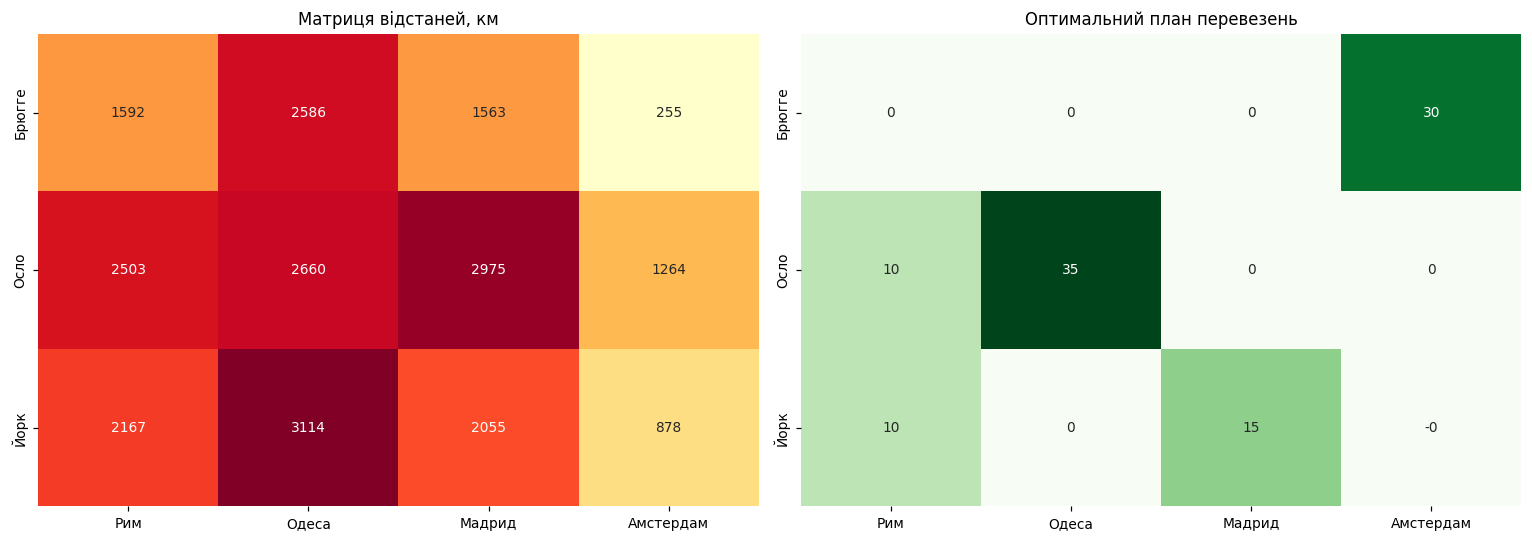

In [26]:
# ВАШ КОД
import seaborn as sns
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Теплова карта відстаней
sns.heatmap(matrix, annot=True, fmt="d", cmap="YlOrRd", 
            xticklabels=споживачі, yticklabels=постачальники, ax=ax1, cbar=False)
ax1.set_title("Матриця відстаней, км")

# Теплова карта плану перевезень
sns.heatmap(plan, annot=True, fmt=".0f", cmap="Greens", 
            xticklabels=споживачі, yticklabels=постачальники, ax=ax2, cbar=False)
ax2.set_title("Оптимальний план перевезень")

plt.tight_layout()
plt.show()

**Висновок:** *(одне речення про те, що видно на теплових картах)*

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [27]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'синтаксис',
    'етап 3, код на Python':                'синтаксис',
    'етапи 4–5, читання та перевірка звіту': 'ні',
    'етап 6, рішення про закупівлю':        'ні',
    'етапи 7–8, перевірка та цілочисельність': 'синтаксис',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = 'перевірив який можна використати другий метод виконання задачі на пайтон, а так само як побудувати теплові діаграми за різними ознаками'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [28]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Бойко Роман
інструменти:                               Gemini
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           синтаксис
етап 3, код на Python:                     синтаксис
етапи 4–5, читання та перевірка звіту:     ні
етап 6, рішення про закупівлю:             ні
етапи 7–8, перевірка та цілочисельність:   синтаксис
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
перевірив який можна використати другий метод виконання задачі на пайтон, а так само як побудувати теплові діаграми за різними ознаками


---
# Крок 13. Фінальна самоперевірка

In [29]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
